1) Проанализируйте переменные (столбцы) и укажите, для каких из них определение
числовых характеристик имеет смысл. Понимать значения всех характеристик, которые дает метод describe().

Не имеющие смысл для числовых характеристик, которые дает метод describe():
Date, Seasons, Holiday, Functioning Day, Temperature Category

2) Для каждого сезона найдите: среднюю, медианную и модовую температуры, дисперсию, среднеквадратичное отклонение, размах и интерквартильный размах
температуры. Результат также выведите в виде общей таблицы.

In [27]:
import pandas as pd
import matplotlib.pyplot as plt

bikes_df = pd.read_csv("DataBikes_new.csv", sep=',')
bikes_df.columns = bikes_df.columns.str.strip()

seasons_groups = bikes_df.groupby('Seasons')['Temperature']

new_numerical_chars = pd.DataFrame({
    "mean": seasons_groups.mean(),
    "median": seasons_groups.median(),
    "mode": seasons_groups.apply(lambda x: x.mode().tolist()),
    "variance": seasons_groups.var(),
    "std": seasons_groups.std().round(3),
    "range": seasons_groups.max() - seasons_groups.min(),
    "IQR": seasons_groups.quantile(0.75) - seasons_groups.quantile(0.25)
})

print(new_numerical_chars)
seasons_groups.describe()

              mean  median                mode   variance    std  range   IQR
Seasons                                                                      
Autumn   14.138821    13.8        [10.8, 16.6]  49.589573  7.042   33.5  11.1
Spring   13.038533    13.3               [9.6]  43.665630  6.608   36.0   9.9
Summer   26.574827    26.6  [23.4, 24.2, 24.6]  21.655814  4.654   23.1   6.7
Winter   -2.567783    -2.2        [-1.8, -1.3]  29.877730  5.466   28.1   7.7


,count,mean,std,min,25%,50%,75%,max
Seasons,,,,,,,,
Autumn,2138.0,14.138821,7.041986,-3.0,8.7,13.8,19.8,30.5
Spring,2154.0,13.038533,6.607997,-6.6,8.2,13.3,18.1,29.4
Summer,2169.0,26.574827,4.653581,16.3,23.1,26.6,29.8,39.4
Winter,2120.0,-2.567783,5.466052,-17.8,-6.2,-2.2,1.5,10.3


3) Переменная «Temperature» содержит None значения. Предложите и реализуйте способ их замены, который по Вашему мнению будет наиболее достоверно соответствовать
реальным условиям. Определите, как изменятся при этом числовые характеристики
среднего и разброса для температуры.

In [28]:
bikes_df.groupby('Seasons')['Temperature'].apply(lambda x: x.isna().sum())  # пустые зачения - True

Seasons
Autumn    46
Spring    54
Summer    39
Winter    40
Name: Temperature, dtype: int64

In [29]:
print("До заполнения")
print(new_numerical_chars)

bikes_df['Date'] = pd.to_datetime(bikes_df['Date'], format="%d/%m/%Y")
bikes_df['Weeks'] = bikes_df['Date'].dt.isocalendar().week  # номера недель в году

weekly_groups = bikes_df.groupby(['Seasons', 'Weeks'])['Temperature']
bikes_df['Temperature'] = weekly_groups.transform(lambda x: x.fillna(x.mean()))

new_groups = bikes_df.groupby('Seasons')['Temperature']

new_chars = pd.DataFrame({
    "mean": new_groups.mean(),
    "median": new_groups.median(),
    "mode": new_groups.apply(lambda x: x.mode().tolist()),
    "variance": new_groups.var(),
    "std": new_groups.std().round(3),
    "IQR": new_groups.quantile(0.75) - new_groups.quantile(0.25)
})

print("\nПосле заполнения")
print(new_chars)
bikes_df.groupby('Seasons')['Temperature'].apply(lambda x: x.isna().sum())

До заполнения
              mean  median                mode   variance    std  range   IQR
Seasons                                                                      
Autumn   14.138821    13.8        [10.8, 16.6]  49.589573  7.042   33.5  11.1
Spring   13.038533    13.3               [9.6]  43.665630  6.608   36.0   9.9
Summer   26.574827    26.6  [23.4, 24.2, 24.6]  21.655814  4.654   23.1   6.7
Winter   -2.567783    -2.2        [-1.8, -1.3]  29.877730  5.466   28.1   7.7

После заполнения
              mean  median                mode   variance    std   IQR
Seasons                                                               
Autumn   14.123849    13.8        [10.8, 16.6]  49.430464  7.031  11.2
Spring   13.051756    13.4               [9.6]  43.104488  6.565   9.7
Summer   26.578690    26.6  [23.4, 24.2, 24.6]  21.444466  4.631   6.7
Winter   -2.554212    -2.2        [-1.8, -1.3]  29.515496  5.433   7.6


Seasons
Autumn    0
Spring    0
Summer    0
Winter    0
Name: Temperature, dtype: int64

4) Предположим, что наблюдения температуры, отклоняющиеся от средней температуры для каждого сезона более чем на два стандартных отклонения, являются выбросами.
Сформируйте таблицу без выбросов. Установить, будет ли наблюдаться отличие в характеристиках средних для температуры, построенных на основе исходной и новой
таблиц.

In [30]:
mean = seasons_groups.transform('mean')
std = seasons_groups.transform('std')

outliers = (bikes_df['Temperature'] - mean).abs() > 2 * std  # нахождение выбросов

no_outliers_df = bikes_df[~outliers].copy()  # копия датафрейма без выбросов
new_seasons_groups = no_outliers_df.groupby('Seasons')['Temperature']

new_numerical_chars = pd.DataFrame({
    "mean": seasons_groups.mean(),
    "new_mean": new_seasons_groups.mean()
})

print(new_numerical_chars)

              mean   new_mean
Seasons                      
Autumn   14.138821  14.181901
Spring   13.038533  13.056604
Summer   26.574827  26.366736
Winter   -2.567783  -2.165256


5) На одном графике построить размах для каждого месяца. Подписать название графика и его оси.

Month
1     26.3
2     23.6
3     28.4
4     25.3
5     22.4
6     16.4
7     20.2
8     19.1
9     19.7
10    24.5
11    22.3
12    20.9
Name: Temperature, dtype: float64


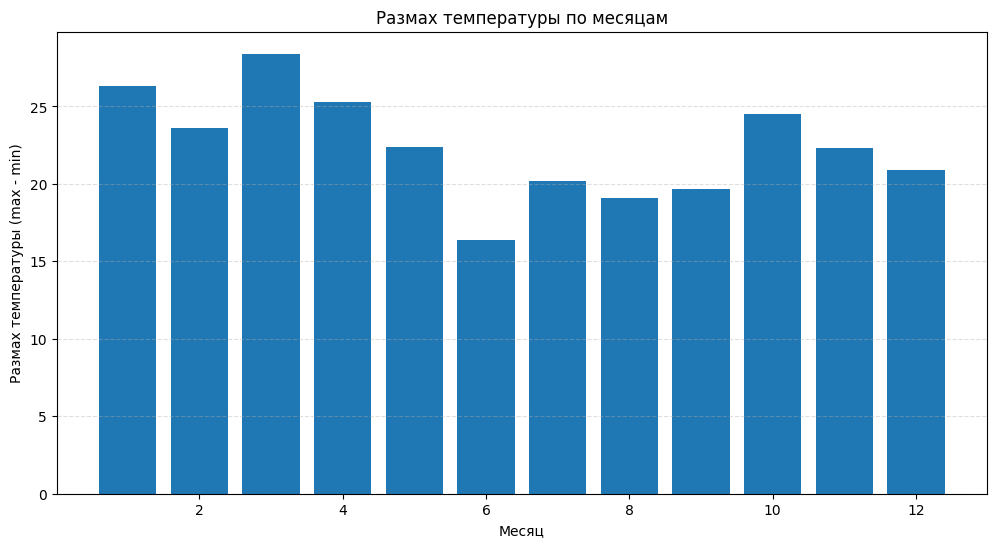

In [31]:
bikes_df['Date'] = pd.to_datetime(bikes_df['Date'], format="%d/%m/%Y")
bikes_df['Month'] = bikes_df['Date'].dt.month  # достать месяца в новый столбец

month_range = bikes_df.groupby('Month')['Temperature'].apply(lambda x: x.max() - x.min())
print(month_range)

# график
plt.figure(figsize=(12, 6))
plt.bar(month_range.index, month_range.values)

plt.title("Размах температуры по месяцам")
plt.xlabel("Месяц")
plt.ylabel("Размах температуры (max - min)")
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.show()

6) Найдите, сколько дней работа проката по оценкам была выше среднего. В этом случае следует учитывать, что оценки выставлялись по разным шкалам, поэтому 10 по одной
шкале это отлично, а по другой очень плохо. Для решения этой проблемы используют так называемую «z-стандартизацию», т. е. вводят новую переменную z = (x - m) / sigma,
которая показывает на сколько среднеквадратичных отклонений, x отклоняется от среднего.

In [32]:
bikes_df['z_score'] = bikes_df.groupby('score_type')['score'].transform(lambda x: (x - x.mean()) / x.std())

bikes_df['above_mean'] = bikes_df['z_score'] > 0

above_mean_count = bikes_df['above_mean'].sum()

print("Кол-во дней, когда оценка была выше среднего:", above_mean_count)

Кол-во дней, когда оценка была выше среднего: 4619


7) Установить наличие линейной зависимости между температурой и числом арендованных велосипедов (по данным за весь год, по сезонам, по месяцам). Для данных,
имеющих максимальную линейную зависимость, построить график рассеяния.

In [33]:
corr_year = bikes_df['Temperature'].corr(bikes_df['Rental count'])
print("Зависимость между температурой и числом арендованных велосипедов за весь год: ", corr_year)

corr_seasons = bikes_df.groupby('Seasons').apply(lambda x: x['Temperature'].corr(x['Rental count']))
print("\nЗависимость между температурой и числом арендованных велосипедов по сезонам:\n", corr_seasons)

corr_month = bikes_df.groupby('Month').apply(lambda y: y['Temperature'].corr(y['Rental count']))
print("\nЗависимость между температурой и числом арендованных велосипедов по месяцам:\n", corr_month, '\n')

Зависимость между температурой и числом арендованных велосипедов за весь год:  0.45373237600101984

Зависимость между температурой и числом арендованных велосипедов по сезонам:
 Seasons
Autumn    0.259261
Spring    0.467423
Summer    0.129669
Winter    0.300005
dtype: float64

Зависимость между температурой и числом арендованных велосипедов по месяцам:
 Month
1     0.301338
2     0.402021
3     0.435379
4     0.504089
5     0.382971
6     0.386667
7     0.245985
8     0.165754
9     0.422444
10    0.207739
11    0.114033
12    0.172816
dtype: float64 



C:\Users\в\AppData\Local\Temp\ipykernel_1872\1672663999.py:4: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  corr_seasons = bikes_df.groupby('Seasons').apply(lambda x: x['Temperature'].corr(x['Rental count']))
C:\Users\в\AppData\Local\Temp\ipykernel_1872\1672663999.py:7: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  corr_month = bikes_df.groupby('Month').apply(lambda y: y['Temperature'].corr(y['Rental count']))


In [34]:
all_corr = pd.concat([pd.Series({'year': corr_year}), corr_seasons.rename(lambda s: f"season_{s}"), corr_month.rename(lambda m: f"month_{m}")])
print(all_corr)

best_label = all_corr.abs().idxmax()
best_value = all_corr.loc[best_label]
#print(best_label)

print("\nМаксимальная зависимость:", best_label, "=", best_value)

year             0.453732
season_Autumn    0.259261
season_Spring    0.467423
season_Summer    0.129669
season_Winter    0.300005
month_1          0.301338
month_2          0.402021
month_3          0.435379
month_4          0.504089
month_5          0.382971
month_6          0.386667
month_7          0.245985
month_8          0.165754
month_9          0.422444
month_10         0.207739
month_11         0.114033
month_12         0.172816
dtype: float64

Максимальная зависимость: month_4 = 0.5040894262526474


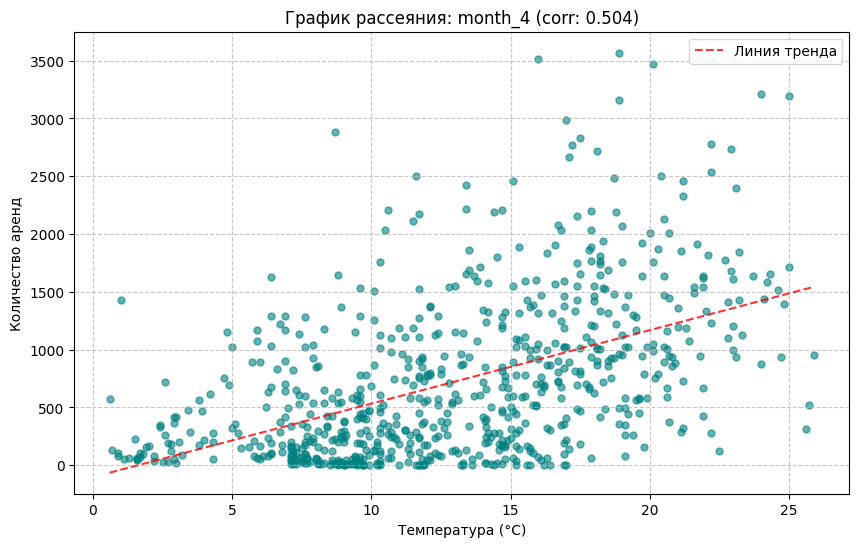

In [ ]:
if best_label == "year":
    plot_df = bikes_df
elif "season_" in best_label:
    season = best_label.replace("season_", "")
    plot_df = bikes_df[bikes_df["Seasons"] == season]
elif "month_" in best_label:
    month = int(best_label.replace("month_", ""))
    plot_df = bikes_df[bikes_df["Month"] == month]

plot_df = plot_df.sort_values("Temperature")

plt.figure(figsize=(10, 6))
plt.scatter(plot_df["Temperature"], plot_df["Rental count"], alpha=0.6, s=25, color='teal')

plt.title(f"График рассеяния: {best_label} (corr: {best_value:.3f})")
plt.xlabel("Температура (°C)")
plt.ylabel("Количество аренд")
plt.grid(True, linestyle='--', alpha=0.7)

import numpy as np
z = np.polyfit(plot_df["Temperature"], plot_df["Rental count"], 1)
p = np.poly1d(z)
plt.plot(plot_df["Temperature"], p(plot_df["Temperature"]), "r--", alpha=0.8, label="Линия тренда")

plt.legend()
plt.show()

8) Аналогичные п.7 исследования провести для температуры и оценки.

In [11]:
corr_year_score = bikes_df["Temperature"].corr(bikes_df["score"])
print("Зависимость между температурой и оценкой за весь год:", corr_year_score)

corr_seasons_score = bikes_df.groupby("Seasons").apply(lambda x: x["Temperature"].corr(x["score"]))
print("\nЗависимость между температурой и оценкой по сезонам:", corr_seasons_score)

corr_month_score = bikes_df.groupby('Month').apply(lambda y: y['Temperature'].corr(y['score']))
print("\nЗависимость между температурой и числом арендованных велосипедов по месяцам:", corr_month_score, '\n')

Зависимость между температурой и оценкой за весь год: -0.010386913681911686

Зависимость между температурой и оценкой по сезонам: Seasons
Autumn   -0.016936
Spring    0.014181
Summer    0.016883
Winter   -0.059530
dtype: float64

Зависимость между температурой и числом арендованных велосипедов по месяцам: Month
1    -0.066727
2    -0.079923
3    -0.040517
4    -0.004832
5     0.081110
6    -0.005725
7    -0.030410
8     0.045480
9     0.012382
10   -0.005105
11   -0.012171
12   -0.018280
dtype: float64 



C:\Users\в\AppData\Local\Temp\ipykernel_1872\2201825004.py:4: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  corr_seasons_score = bikes_df.groupby("Seasons").apply(lambda x: x["Temperature"].corr(x["score"]))
C:\Users\в\AppData\Local\Temp\ipykernel_1872\2201825004.py:7: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  corr_month_score = bikes_df.groupby('Month').apply(lambda y: y['Temperature'].corr(y['score']))


In [12]:
all_corr_score = pd.concat([pd.Series({'year': corr_year_score}), corr_seasons_score.rename(lambda s: f"season_{s}"), corr_month_score.rename(lambda m: f"month_{m}")])
print(all_corr_score)

best_label_score = all_corr_score.abs().idxmax()
best_value_score = all_corr_score.loc[best_label_score]

print("\nМаксимальная зависимость:", best_label_score, "=", best_value_score)

year            -0.010387
season_Autumn   -0.016936
season_Spring    0.014181
season_Summer    0.016883
season_Winter   -0.059530
month_1         -0.066727
month_2         -0.079923
month_3         -0.040517
month_4         -0.004832
month_5          0.081110
month_6         -0.005725
month_7         -0.030410
month_8          0.045480
month_9          0.012382
month_10        -0.005105
month_11        -0.012171
month_12        -0.018280
dtype: float64

Максимальная зависимость: month_5 = 0.08110985510973516


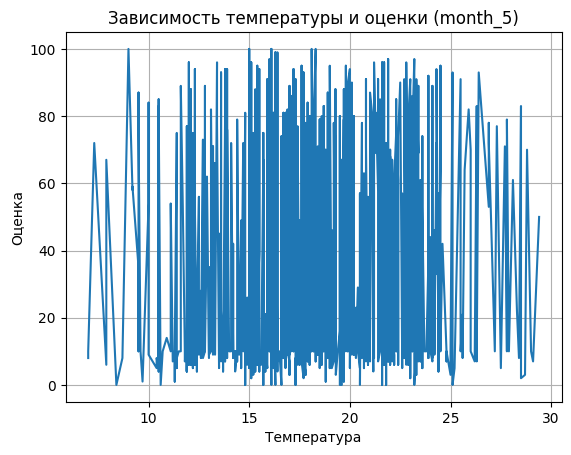

In [13]:
if best_label_score == "year":
    plot_df = bikes_df
elif "season_" in best_label_score:
    s = best_label_score.replace("season_", "")
    plot_df = bikes_df[bikes_df["Seasons"] == s]
elif "month_" in best_label_score:
    m = int(best_label_score.replace("month_", ""))
    plot_df = bikes_df[bikes_df["Month"] == m]


plot_df = plot_df.sort_values("Temperature")

plt.plot(plot_df["Temperature"], plot_df["score"])
plt.title(f"Зависимость температуры и оценки ({best_label_score})")
plt.xlabel("Температура")
plt.ylabel("Оценка")
plt.grid(True)
plt.show()
